# AA3 · Parcial II · Cuaderno 3: Transformers
**Alumno:** Santiago Romo Rubio
**Datos:** temática opcional, mesa de ayuda de una universidad ficticia: cada mensaje de un estudiante se convierte en un ticket JSON
**Opción:** LoRA

Ajuste con **LoRA** de `Qwen/Qwen2.5-0.5B-Instruct` (Práctica 6) para convertir el mensaje de un estudiante en un ticket con cinco campos:

```json
{"nombre": "Ana López", "id_alumno": "A1023", "area": "finanzas", "asunto": "adeudo de colegiatura", "urgente": false}
```

Se compara contra el mismo modelo **sin ajustar**, con un *prompt* corto y con un *prompt* con reglas. **Todos los datos son ficticios.**

## 1. Datos
**Entorno.** El modelo corre en **float32**: la serie GTX 16xx de la máquina local tiene antecedentes de valores NaN con media precisión, y en una T4 también funciona.

In [1]:
import importlib.util
import os
import subprocess
import sys

if importlib.util.find_spec("peft") is None:  # Colab trae transformers, pero no siempre peft
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "peft"])

os.environ["USE_TF"] = "0"  # transformers: usar PyTorch, no TensorFlow
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import gc
import json
import random
import re
import time
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers

SEED = 42
transformers.set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
GPU = torch.cuda.is_available()
DISPOSITIVO = "cuda" if GPU else "cpu"
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)

print(f"Python {sys.version.split()[0]} · PyTorch {torch.__version__} · transformers {transformers.__version__} · peft {peft.__version__}")
print(f"GPU: {torch.cuda.get_device_name(0) if GPU else 'no disponible'}")

Python 3.11.16 · PyTorch 2.5.1+cu121 · transformers 5.17.0 · peft 0.21.2
GPU: NVIDIA GeForce GTX 1660 SUPER


**La tarea.** Cada ticket tiene cinco campos verificables:

| Campo | Valor |
|---|---|
| `nombre` | El nombre del estudiante tal como lo escribe, o `null` si no lo da |
| `id_alumno` | La matrícula en mayúsculas (`A` + 4 dígitos), o `null` si no la da |
| `area` | `escolares`, `finanzas`, `sistemas` o `seguridad` |
| `asunto` | Uno de los 16 asuntos del catálogo de abajo (4 por área) |
| `urgente` | `true` si es una emergencia de seguridad o si el mensaje dice que es urgente o que vence hoy |

Si el mensaje trae **dos temas**, el ticket es del que se menciona primero, salvo que uno sea una emergencia de seguridad: esa siempre va primero.

**Entrenamiento y validación (200 pares).** Se generan con **plantillas**, como en las prácticas: cada asunto tiene dos o tres redacciones, a las que se agregan una presentación con nombre y matrícula (a veces falta uno de los dos), saludos, cierres, una marca de urgencia en el 20 % de los mensajes que no son de seguridad y algo de ruido (minúsculas, sin acentos). La celda siguiente contiene el generador completo.

In [2]:
CATALOGO = {
    "escolares": {
        "inscripción de materias": ["no me deja inscribir las materias de {semestre}", "no aparecen mis materias para inscribirme en {semestre}",
                                    "el sistema no me deja dar de alta mis materias de {semestre}"],
        "constancia de estudios": ["necesito una constancia de estudios {plazo}", "ocupo una constancia de que estoy inscrito {plazo}",
                                   "quisiera solicitar una constancia de estudios {plazo}"],
        "cambio de grupo": ["quiero cambiarme de grupo en {materia}", "el horario de {materia} me choca con el trabajo, quiero cambiar de grupo",
                            "¿puedo pasarme a otro grupo de {materia}?"],
        "revisión de calificación": ["mi calificación de {materia} está mal capturada", "quiero pedir revisión de mi calificación de {materia}",
                                     "en el sistema aparece una calificación de {materia} que no es la mía"],
    },
    "finanzas": {
        "adeudo de colegiatura": ["ya pagué la colegiatura y me sigue saliendo adeudo", "me aparece un adeudo de colegiatura que ya pagué",
                                  "el sistema dice que debo la colegiatura pero ya la pagué"],
        "renovación de beca": ["quiero saber cómo renovar mi beca", "no me renovaron la beca de este semestre",
                               "¿cuándo es el trámite de renovación de beca?"],
        "factura de colegiatura": ["necesito la factura de mi colegiatura", "no me ha llegado la factura del pago de colegiatura",
                                   "¿me pueden mandar la factura de la colegiatura?"],
        "cobro duplicado": ["me cobraron dos veces la colegiatura", "me hicieron un cargo doble en la tarjeta por la colegiatura",
                            "pagué una vez y me aparecen dos cobros"],
    },
    "sistemas": {
        "acceso a Moodle": ["no puedo entrar a Moodle, dice que mi contraseña está mal", "Moodle no me deja iniciar sesión",
                            "se me bloqueó la cuenta de Moodle"],
        "correo institucional": ["no puedo entrar a mi correo institucional", "mi correo de la universidad no recibe mensajes",
                                 "el correo institucional me marca error al iniciar sesión"],
        "wifi del campus": ["el wifi del campus no me conecta", "no tengo internet en {lugar}, el wifi no funciona",
                            "la red inalámbrica de la universidad no me deja conectarme"],
        "error en el portal de alumnos": ["el portal de alumnos marca error", "no carga el portal de alumnos",
                                          "el portal de alumnos se cae cuando quiero ver mi horario"],
    },
    "seguridad": {
        "persona desmayada": ["un compañero se desmayó en {lugar}", "una chica se desmayó en {lugar} y no reacciona",
                              "se desmayó un maestro en {lugar}"],
        "robo": ["me robaron la mochila en {lugar}", "acaban de robar una computadora en {lugar}", "me quitaron el celular en {lugar}"],
        "incendio": ["sale humo de {lugar}", "hay fuego en {lugar}", "se está quemando algo en {lugar}"],
        "persona herida": ["alguien se cayó en las escaleras de {lugar} y está sangrando", "un compañero se cortó la mano en {lugar}",
                           "una persona se golpeó la cabeza en {lugar}"],
    },
}
AREAS = list(CATALOGO)
ASUNTOS = [a for area in CATALOGO.values() for a in area]
CAMPOS = ["nombre", "id_alumno", "area", "asunto", "urgente"]

NOMBRES = ["Ana", "Carlos", "María", "José", "Laura", "Miguel", "Carmen", "Jorge", "Patricia", "Raúl", "Beatriz", "Sergio",
           "Adriana", "Manuel", "Verónica", "Alejandro", "Claudia", "Eduardo", "Gloria", "Rafael", "Teresa", "Javier", "Mónica", "Hugo"]
APELLIDOS = ["López", "García", "Martínez", "Hernández", "González", "Pérez", "Sánchez", "Romero", "Jiménez", "Morales",
             "Delgado", "Castillo", "Guerrero", "Medina", "Rojas", "Cabrera", "Domínguez", "Silva", "Fuentes", "Acosta"]
SEMESTRES = ["séptimo", "tercero", "quinto", "primer semestre", "octavo"]
MATERIAS = ["Cálculo", "Estadística", "Programación", "Física", "Contabilidad", "Inglés", "Ética", "Microeconomía"]
LUGARES = ["el laboratorio de química", "la biblioteca", "la cafetería", "el estacionamiento", "el gimnasio", "el edificio F",
           "el salón 204", "el auditorio"]
PLAZOS = ["para el viernes", "para la próxima semana", "para un trámite", "para mi trabajo", ""]
URGENCIAS = [" Es urgente.", " Lo necesito hoy, es urgente.", " Hoy vence el plazo.", " Por favor, es urgente."]
SALUDOS = ["", "", "Hola, ", "Buenas tardes, ", "Buen día, ", "Hola, buenas noches. "]
CIERRES = ["", "", " Gracias.", " Saludos.", " Quedo pendiente."]


def presentacion(nombre, id_alumno, rng):
    if nombre and id_alumno:
        return rng.choice([f"Soy {nombre}, matrícula {id_alumno}.", f"Mi nombre es {nombre} y mi matrícula es {id_alumno}.",
                           f"{nombre} ({id_alumno}).", f"Habla {nombre}, ID {id_alumno}."])
    if nombre:
        return rng.choice([f"Soy {nombre}.", f"Mi nombre es {nombre}."])
    return rng.choice([f"Mi matrícula es {id_alumno}.", f"Matrícula {id_alumno}."])


def sin_acentos(t):
    return "".join(c for c in unicodedata.normalize("NFD", t) if unicodedata.category(c) != "Mn")


def generar(n, semilla=SEED):
    rng = random.Random(semilla)
    pares, vistos = [], set()
    while len(pares) < n:
        area = AREAS[len(pares) % len(AREAS)]  # balanceado por área
        asunto = rng.choice(list(CATALOGO[area]))
        problema = rng.choice(CATALOGO[area][asunto]).format(semestre=rng.choice(SEMESTRES), materia=rng.choice(MATERIAS),
                                                             lugar=rng.choice(LUGARES), plazo=rng.choice(PLAZOS)).strip()
        problema = problema[0].upper() + problema[1:] + ("" if problema.endswith(("?", ".")) else ".")
        nombre = f"{rng.choice(NOMBRES)} {rng.choice(APELLIDOS)}" if rng.random() > 0.07 else None
        id_alumno = f"A{rng.randint(1000, 3999)}" if (rng.random() > 0.12 or nombre is None) else None
        urgente = area == "seguridad" or rng.random() < 0.2
        marca = rng.choice(URGENCIAS) if urgente and area != "seguridad" else ""
        quien = presentacion(nombre, id_alumno, rng)
        if rng.random() < 0.5:
            texto = f"{rng.choice(SALUDOS)}{quien} {problema}{marca}{rng.choice(CIERRES)}"
        else:
            texto = f"{rng.choice(SALUDOS)}{problema}{marca} {quien}{rng.choice(CIERRES)}"
        if rng.random() < 0.2:
            texto = texto.lower()
        if rng.random() < 0.2:
            texto = sin_acentos(texto)
        texto = " ".join(texto.split())
        if texto in vistos:
            continue
        vistos.add(texto)
        ticket = {"nombre": nombre, "id_alumno": id_alumno, "area": area, "asunto": asunto, "urgente": urgente}
        pares.append((texto, ticket))
    return pares


PARES = generar(200)
PARES_TRAIN, PARES_VAL = PARES[:160], PARES[160:]
print(f"Pares generados: {len(PARES)} · entrenamiento: {len(PARES_TRAIN)} · validación: {len(PARES_VAL)}")
for texto, ticket in PARES[:4]:
    print(f"\n  {texto}\n  → {json.dumps(ticket, ensure_ascii=False)}")

Pares generados: 200 · entrenamiento: 160 · validación: 40

  Soy Javier Silva. No me deja inscribir las materias de quinto. Quedo pendiente.
  → {"nombre": "Javier Silva", "id_alumno": null, "area": "escolares", "asunto": "inscripción de materias", "urgente": false}

  Hola, Soy Beatriz Jimenez, matricula A2378. Me cobraron dos veces la colegiatura. Por favor, es urgente. Quedo pendiente.
  → {"nombre": "Beatriz Jiménez", "id_alumno": "A2378", "area": "finanzas", "asunto": "cobro duplicado", "urgente": true}

  Soy Teresa Acosta, matrícula A2481. El portal de alumnos se cae cuando quiero ver mi horario. Gracias.
  → {"nombre": "Teresa Acosta", "id_alumno": "A2481", "area": "sistemas", "asunto": "error en el portal de alumnos", "urgente": false}

  Una chica se desmayo en el edificio F y no reacciona. Soy Carmen Jimenez, matricula A3799. Quedo pendiente.
  → {"nombre": "Carmen Jiménez", "id_alumno": "A3799", "area": "seguridad", "asunto": "persona desmayada", "urgente": true}


**Revisión a mano del generador.** Leí una muestra de los pares para confirmar que cada mensaje dice lo que su ticket. La tabla resume la distribución y la celda verifica, para todos los pares, que el ticket es consistente con las reglas: que la matrícula y el nombre aparecen en el mensaje y que toda emergencia de seguridad es urgente.

In [3]:
for texto, t in PARES:
    assert t["area"] in AREAS and t["asunto"] in CATALOGO[t["area"]]
    assert t["id_alumno"] is None or t["id_alumno"].lower() in texto.lower()
    assert t["nombre"] is None or sin_acentos(t["nombre"]).lower() in sin_acentos(texto).lower()
    assert t["urgente"] or t["area"] != "seguridad"
    assert t["nombre"] or t["id_alumno"]
print("Los 200 tickets son consistentes con sus mensajes.")

df_pares = pd.DataFrame([t for _, t in PARES])
display(pd.crosstab(df_pares["area"], df_pares["urgente"], margins=True, margins_name="Total"))
print(f"Sin nombre: {df_pares['nombre'].isna().sum()} · sin matrícula: {df_pares['id_alumno'].isna().sum()}")
display(pd.DataFrame(PARES[:10], columns=["Mensaje", "Ticket"]).assign(Ticket=lambda d: d["Ticket"].map(lambda t: json.dumps(t, ensure_ascii=False))))

Los 200 tickets son consistentes con sus mensajes.


urgente,False,True,Total
area,,,
escolares,47,3,50
finanzas,46,4,50
seguridad,0,50,50
sistemas,41,9,50
Total,134,66,200


Sin nombre: 15 · sin matrícula: 25


,Mensaje,Ticket
0,Soy Javier Silva. No me deja inscribir las materias de quinto. Quedo pendiente.,"{""nombre"": ""Javier Silva"", ""id_alumno"": null, ""area"": ""escolares"", ""asunto"": ""inscripción de materias"", ""urgente"": false}"
1,"Hola, Soy Beatriz Jimenez, matricula A2378. Me cobraron dos veces la colegiatura. Por favor, es urgente. Quedo pendiente.","{""nombre"": ""Beatriz Jiménez"", ""id_alumno"": ""A2378"", ""area"": ""finanzas"", ""asunto"": ""cobro duplicado"", ""urgente"": true}"
2,"Soy Teresa Acosta, matrícula A2481. El portal de alumnos se cae cuando quiero ver mi horario. Gracias.","{""nombre"": ""Teresa Acosta"", ""id_alumno"": ""A2481"", ""area"": ""sistemas"", ""asunto"": ""error en el portal de alumnos"", ""urgente"": false}"
3,"Una chica se desmayo en el edificio F y no reacciona. Soy Carmen Jimenez, matricula A3799. Quedo pendiente.","{""nombre"": ""Carmen Jiménez"", ""id_alumno"": ""A3799"", ""area"": ""seguridad"", ""asunto"": ""persona desmayada"", ""urgente"": true}"
4,"Buenas tardes, Carlos Delgado (A1271). Quiero pedir revisión de mi calificación de Física. Saludos.","{""nombre"": ""Carlos Delgado"", ""id_alumno"": ""A1271"", ""area"": ""escolares"", ""asunto"": ""revisión de calificación"", ""urgente"": false}"
5,"No me renovaron la beca de este semestre. Soy Gloria Guerrero, matrícula A1566.","{""nombre"": ""Gloria Guerrero"", ""id_alumno"": ""A1566"", ""area"": ""finanzas"", ""asunto"": ""renovación de beca"", ""urgente"": false}"
6,"Buen día, El portal de alumnos se cae cuando quiero ver mi horario. Soy Claudia Jiménez, matrícula A1047. Gracias.","{""nombre"": ""Claudia Jiménez"", ""id_alumno"": ""A1047"", ""area"": ""sistemas"", ""asunto"": ""error en el portal de alumnos"", ""urgente"": false}"
7,"buen día, hay fuego en el laboratorio de química. miguel domínguez (a3561). quedo pendiente.","{""nombre"": ""Miguel Domínguez"", ""id_alumno"": ""A3561"", ""area"": ""seguridad"", ""asunto"": ""incendio"", ""urgente"": true}"
8,Quisiera solicitar una constancia de estudios para mi trabajo. Mi matrícula es A2259.,"{""nombre"": null, ""id_alumno"": ""A2259"", ""area"": ""escolares"", ""asunto"": ""constancia de estudios"", ""urgente"": false}"
9,"Hola, buenas noches. Manuel Sánchez (A3989). Quiero saber cómo renovar mi beca. Gracias.","{""nombre"": ""Manuel Sánchez"", ""id_alumno"": ""A3989"", ""area"": ""finanzas"", ""asunto"": ""renovación de beca"", ""urgente"": false}"


**Prueba escrita aparte (30 casos).** La escribí a mano, sin el generador y **con otro estilo**: faltas de ortografía, abreviaturas («xq», «kiero», «biblio»), emojis, matrículas en minúsculas, mensajes con **dos temas a la vez**, otra forma de presentarse y nombres que no están en las listas del generador. El modelo nunca ve estos mensajes durante el ajuste.

In [4]:
def T(texto, nombre, id_alumno, area, asunto, urgente):
    return (texto, {"nombre": nombre, "id_alumno": id_alumno, "area": area, "asunto": asunto, "urgente": urgente})


PRUEBA = [
    T("ola buenas, soy karla mendez a2291 y no me deja inscrivir las materias de 5to semestre, ya intente 3 veces",
      "Karla Méndez", "A2291", "escolares", "inscripción de materias", False),
    T("Ya pague la colegiatura desde el lunes y en el portal sigo debiendo. Tambien quiero saber si ya salio lo de mi beca. Luis Ortega A1187",
      "Luis Ortega", "A1187", "finanzas", "adeudo de colegiatura", False),
    T("AYUDA en la cafe un chavo se desmayo y no responde!!! soy andrea, A3310",
      "Andrea", "A3310", "seguridad", "persona desmayada", True),
    T("no puedo entrar a moodle me dice contraseña incorrecta y tengo examen en linea en una hora, urge. Diego Salas a1450",
      "Diego Salas", "A1450", "sistemas", "acceso a Moodle", True),
    T("buen dia, me podrian hacer una constancia de estudios? la piden en mi trabajo para la otra semana. att: Mariana Ruiz Peña, matricula A2077",
      "Mariana Ruiz Peña", "A2077", "escolares", "constancia de estudios", False),
    T("me cobraron doble la colegiatura en la tarjeta 😡 y aparte el wifi de la biblio no sirve. Héctor Lara (A1902)",
      "Héctor Lara", "A1902", "finanzas", "cobro duplicado", False),
    T("Hay humo saliendo del laboratorio de quimica y huele a quemado, tambien me falta mi constancia. Soy Paola Ríos A2650",
      "Paola Ríos", "A2650", "seguridad", "incendio", True),
    T("Profe, mi calificacion de estadistica salio 5 y yo saque 8 en el final, quien me ayuda? Rodrigo Nava A1733",
      "Rodrigo Nava", "A1733", "escolares", "revisión de calificación", False),
    T("no me llega nada al correo de la uni desde ayer, ni los avisos. sofia herrera",
      "Sofía Herrera", None, "sistemas", "correo institucional", False),
    T("Necesito factura de lo que pagué de colegiatura este mes, mi RFC lo mando después. Iván Castro, A2810",
      "Iván Castro", "A2810", "finanzas", "factura de colegiatura", False),
    T("en el estacionamiento me abrieron el coche y se llevaron mi lap. A1555 Fernanda Gil",
      "Fernanda Gil", "A1555", "seguridad", "robo", True),
    T("quiero cambiarme al grupo de la tarde de programación porque entro a trabajar a las 8, se puede? Emilio Vargas A3021",
      "Emilio Vargas", "A3021", "escolares", "cambio de grupo", False),
    T("El portal de alumnos no abre, sale error y hoy es el ultimo dia para subir documentos!! Valeria Soto A1290",
      "Valeria Soto", "A1290", "sistemas", "error en el portal de alumnos", True),
    T("No me renovaron la beca y ya empezó el semestre, ¿qué hago? Gabriel Mora, A2444",
      "Gabriel Mora", "A2444", "finanzas", "renovación de beca", False),
    T("una compañera se cayo de las escaleras del edificio F y le sale sangre de la cabeza, vengan rapido. Tomás Aguilar",
      "Tomás Aguilar", None, "seguridad", "persona herida", True),
    T("wifi del campus no conecta en ningun salon desde la mañana, ni con mi cel ni con la compu. Natalia Cruz A1608",
      "Natalia Cruz", "A1608", "sistemas", "wifi del campus", False),
    T("hola, el sistema no me deja dar de alta Física II y tampoco me sale la constancia. Jimena Paredes A2902",
      "Jimena Paredes", "A2902", "escolares", "inscripción de materias", False),
    T("Mi matrícula es A1375. Ya pague y me sigue apareciendo adeudo, me van a bloquear la inscripción hoy si no se arregla, urgente",
      None, "A1375", "finanzas", "adeudo de colegiatura", True),
    T("se me olvido mi contraseña de moodle y no puedo reestablecerla, Ricardo Peña A2177",
      "Ricardo Peña", "A2177", "sistemas", "acceso a Moodle", False),
    T("Buenas noches. Soy Daniela Ortiz (a2533). Saqué 9 en el examen de contabilidad pero en el sistema tengo 6, pido revisión",
      "Daniela Ortiz", "A2533", "escolares", "revisión de calificación", False),
    T("Me robaron la cartera en el gym hace rato, alguien de seguridad? Mauricio León A3140",
      "Mauricio León", "A3140", "seguridad", "robo", True),
    T("necesito constancia de estudios HOY para el seguro de mi mamá, es urgente!! Ximena Flores A1820",
      "Ximena Flores", "A1820", "escolares", "constancia de estudios", True),
    T("pague dos veces la reinscripcion por error, como pido que me regresen uno? Óscar Ibarra A2365",
      "Óscar Ibarra", "A2365", "finanzas", "cobro duplicado", False),
    T("el correo institucional me rebota todos los mensajes y además no puedo entrar a Moodle. Lucía Serrano A1499",
      "Lucía Serrano", "A1499", "sistemas", "correo institucional", False),
    T("Un señor se desmayó en el estacionamiento, está en el piso, no sé qué hacer. Soy Alberto Ramos, A2710",
      "Alberto Ramos", "A2710", "seguridad", "persona desmayada", True),
    T("kiero cambiarme de grupo de ingles xq el profe no se presenta. Samuel Torres a1066",
      "Samuel Torres", "A1066", "escolares", "cambio de grupo", False),
    T("No me llegó la factura de la colegiatura de septiembre, la necesito para deducir impuestos. Regina Campos A2588",
      "Regina Campos", "A2588", "finanzas", "factura de colegiatura", False),
    T("el portal d alumnos se queda cargando y no puedo ver mi horario. Bruno Esquivel A3307",
      "Bruno Esquivel", "A3307", "sistemas", "error en el portal de alumnos", False),
    T("Se está quemando un contacto en el salón 204, sale chispa y humo!! Elena Vega A1944",
      "Elena Vega", "A1944", "seguridad", "incendio", True),
    T("Holi, quiero renovar mi beca pero no encuentro el formato, y también tengo un adeudo raro. Pablo Juárez A2219",
      "Pablo Juárez", "A2219", "finanzas", "renovación de beca", False),
]

assert all(t["asunto"] in CATALOGO[t["area"]] for _, t in PRUEBA)
fuga = {m for m, _ in PRUEBA} & {m for m, _ in PARES}
assert not fuga, "Hay mensajes de prueba dentro del entrenamiento"
df_prueba = pd.DataFrame([t for _, t in PRUEBA])
print(f"Prueba: {len(PRUEBA)} casos · por área: {df_prueba['area'].value_counts().to_dict()} · urgentes: {int(df_prueba['urgente'].sum())}")
print(f"Nombres de la prueba que también están en el generador: {sum(n.split()[0] in NOMBRES for n in df_prueba['nombre'].dropna())}")

Prueba: 30 casos · por área: {'escolares': 8, 'finanzas': 8, 'seguridad': 7, 'sistemas': 7} · urgentes: 11
Nombres de la prueba que también están en el generador: 0


## 2. Línea base
El mismo modelo **sin ajustar**, en dos variantes, siempre con temperatura 0:
- ***Prompt* corto:** solo pide el ticket y nombra los campos.
- ***Prompt* con reglas:** describe cada campo, da las cuatro áreas, el catálogo de 16 asuntos, la regla de urgencia, la de los dos temas y pide responder solo con el JSON.

**Métricas** (las mismas para las tres configuraciones, en los 30 casos de prueba):
- **JSON válido:** la respuesta completa se puede leer con `json.loads` y trae exactamente los cinco campos.
- **Exactitud por campo:** si el campo coincide con el ticket correcto. Para no castigar dos veces el formato, aquí se acepta un JSON envuelto en texto o en bloque de código, y los textos se comparan sin mayúsculas ni acentos. Una respuesta sin JSON cuenta como error en los cinco campos.
- **Ticket exacto:** los cinco campos correctos a la vez. Es la métrica principal: un ticket con un campo mal se va al área equivocada o pierde la urgencia.

In [5]:
from transformers import AutoModelForCausalLM, AutoTokenizer

NOMBRE_LLM = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(NOMBRE_LLM)
tok.padding_side = "left"  # para generar por lotes


def cargar_base():
    return AutoModelForCausalLM.from_pretrained(NOMBRE_LLM, dtype=torch.float32).to(DISPOSITIVO)


PROMPT_CORTO = "Convierte el mensaje del estudiante en un ticket JSON con los campos nombre, id_alumno, area, asunto y urgente."

lista_asuntos = "\n".join(f'  - {area}: {", ".join(chr(34) + a + chr(34) for a in asuntos)}' for area, asuntos in CATALOGO.items())
PROMPT_REGLAS = f"""Eres el sistema de la mesa de ayuda de una universidad. Convierte el mensaje del estudiante en un ticket JSON con exactamente estos cinco campos:
- "nombre": el nombre del estudiante como aparece en el mensaje, o null si no lo da.
- "id_alumno": la matrícula en mayúsculas (una A seguida de 4 dígitos), o null si no la da.
- "area": una de "escolares", "finanzas", "sistemas" o "seguridad".
- "asunto": exactamente uno de estos asuntos, según el área:
{lista_asuntos}
- "urgente": true si es una emergencia de seguridad o si el mensaje dice que es urgente o que vence hoy; si no, false.
Si el mensaje trae dos temas, usa el primero que se menciona, salvo que uno sea una emergencia de seguridad: esa va primero.
Responde solo con el JSON en una línea, sin texto adicional ni bloques de código.
Ejemplo de formato: {{"nombre": "Ana López", "id_alumno": "A1023", "area": "finanzas", "asunto": "adeudo de colegiatura", "urgente": false}}"""
print(PROMPT_REGLAS)


def mensajes(texto, sistema):
    return [{"role": "system", "content": sistema}, {"role": "user", "content": texto}]


def generar_respuestas(modelo, textos, sistema, lote=8, max_nuevos=96):
    """Respuesta de cada mensaje con temperatura 0 (decodificación voraz)."""
    modelo.eval()
    salidas = []
    for i in range(0, len(textos), lote):
        prompts = [tok.apply_chat_template(mensajes(t, sistema), tokenize=False, add_generation_prompt=True) for t in textos[i : i + lote]]
        ent = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(modelo.device)
        with torch.no_grad():
            sal = modelo.generate(**ent, max_new_tokens=max_nuevos, do_sample=False, temperature=None, top_p=None, top_k=None,
                                  pad_token_id=tok.pad_token_id)
        salidas += [t.strip() for t in tok.batch_decode(sal[:, ent["input_ids"].shape[1] :], skip_special_tokens=True)]
    return salidas


def leer_json(texto, estricto=False):
    """Devuelve el dict del ticket o None. En modo flexible acepta un bloque de código o texto alrededor del JSON."""
    try:
        d = json.loads(texto.strip())
        if isinstance(d, dict):
            return d
    except json.JSONDecodeError:
        pass
    if estricto:
        return None
    m = re.search(r"\{.*?\}", texto, flags=re.DOTALL)
    if m:
        try:
            d = json.loads(m.group(0))
            return d if isinstance(d, dict) else None
        except json.JSONDecodeError:
            return None
    return None


def normalizar(v):
    if isinstance(v, str):
        v = " ".join(sin_acentos(v).casefold().split())
        return {"null": None, "": None, "none": None, "true": True, "false": False}.get(v, v)
    return v


def calificar(salida, esperado):
    estricto = leer_json(salida, estricto=True)
    d = leer_json(salida) or {}
    fila = {"JSON válido": estricto is not None and set(estricto) == set(CAMPOS)}
    for c in CAMPOS:
        fila[c] = c in d and normalizar(d[c]) == normalizar(esperado[c])
    fila["Ticket exacto"] = all(fila[c] for c in CAMPOS)
    return fila


# Comprobación de la métrica: el ticket correcto pasa, un campo cambiado se detecta
_t = PRUEBA[0][1]
assert calificar(json.dumps(_t, ensure_ascii=False), _t)["Ticket exacto"]
assert calificar("```json\n" + json.dumps(_t) + "\n```", _t) == {**calificar(json.dumps(_t), _t), "JSON válido": False}
assert not calificar(json.dumps({**_t, "area": "sistemas"}), _t)["Ticket exacto"]
print("Métrica verificada.")

textos_prueba = [m for m, _ in PRUEBA]
esperados = [t for _, t in PRUEBA]
salidas, filas = {}, {}


def evaluar(nombre, modelo, sistema):
    t0 = time.time()
    salidas[nombre] = generar_respuestas(modelo, textos_prueba, sistema)
    seg = (time.time() - t0) / len(textos_prueba)
    calif = pd.DataFrame([calificar(s, e) for s, e in zip(salidas[nombre], esperados)])
    filas[nombre] = {**calif.mean().to_dict(), "s/mensaje": seg}
    return calif


llm_base = cargar_base()
print(f"{NOMBRE_LLM}: {llm_base.num_parameters() / 1e6:.0f} M de parámetros, {next(llm_base.parameters()).dtype}")

Eres el sistema de la mesa de ayuda de una universidad. Convierte el mensaje del estudiante en un ticket JSON con exactamente estos cinco campos:
- "nombre": el nombre del estudiante como aparece en el mensaje, o null si no lo da.
- "id_alumno": la matrícula en mayúsculas (una A seguida de 4 dígitos), o null si no la da.
- "area": una de "escolares", "finanzas", "sistemas" o "seguridad".
- "asunto": exactamente uno de estos asuntos, según el área:
  - escolares: "inscripción de materias", "constancia de estudios", "cambio de grupo", "revisión de calificación"
  - finanzas: "adeudo de colegiatura", "renovación de beca", "factura de colegiatura", "cobro duplicado"
  - sistemas: "acceso a Moodle", "correo institucional", "wifi del campus", "error en el portal de alumnos"
  - seguridad: "persona desmayada", "robo", "incendio", "persona herida"
- "urgente": true si es una emergencia de seguridad o si el mensaje dice que es urgente o que vence hoy; si no, false.
Si el mensaje trae dos temas,

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen/Qwen2.5-0.5B-Instruct: 494 M de parámetros, torch.float32


In [6]:
M_CORTO, M_REGLAS, M_LORA = "Sin ajustar · prompt corto", "Sin ajustar · prompt con reglas", "LoRA (r = 16, 3 épocas) · prompt corto"
calif_corto = evaluar(M_CORTO, llm_base, PROMPT_CORTO)
calif_reglas = evaluar(M_REGLAS, llm_base, PROMPT_REGLAS)
display(pd.DataFrame(filas).T.style.format({c: "{:.0%}" for c in ["JSON válido", *CAMPOS, "Ticket exacto"]} | {"s/mensaje": "{:.2f}"}))

print("Primeras respuestas de la línea base:")
for i in range(4):
    print(f"\n- {textos_prueba[i]}\n  corto : {salidas[M_CORTO][i][:230]}\n  reglas: {salidas[M_REGLAS][i][:230]}")
del llm_base
gc.collect()
if GPU:
    torch.cuda.empty_cache()

,JSON válido,nombre,id_alumno,area,asunto,urgente,Ticket exacto,s/mensaje
Sin ajustar · prompt corto,0%,87%,93%,0%,3%,43%,0%,0.43
Sin ajustar · prompt con reglas,100%,97%,93%,40%,27%,90%,7%,0.34


Primeras respuestas de la línea base:

- ola buenas, soy karla mendez a2291 y no me deja inscrivir las materias de 5to semestre, ya intente 3 veces
  corto : Aquí tienes la información convertida en un ticket JSON:

```json
{
  "nombre": "Karla Mendez",
  "id_alumno": "A2291",
  "area": "Matemáticas",
  "asunto": "Rechazo de inscripción para 5to Semestre",
  "urgente": true
}
```

Este
  reglas: {"nombre": "Karla Mendez", "id_alumno": "A2291", "area": "escolares", "asunto": "inactividad en sistema", "urgente": true}

- Ya pague la colegiatura desde el lunes y en el portal sigo debiendo. Tambien quiero saber si ya salio lo de mi beca. Luis Ortega A1187
  corto : Aquí tienes una versión de tu mensaje convertido en un Ticket JSON:

```json
{
  "nombre": "Luis Ortega",
  "id_alumno": "A1187",
  "area": "Colegiatura",
  "asunto": "Pendiente: Salida de Beca",
  "urgente": true
}
```

Este Tick
  reglas: {"nombre": "Luis Ortega", "id_alumno": "A1187", "area": "finanzas", "asunto": "debe de pa

## 3. Modelo
**LoRA** congela los 494 M de pesos de Qwen y agrega, a cada proyección de atención (`q_proj`, `k_proj`, `v_proj`, `o_proj`), dos matrices pequeñas de rango **r = 16** cuyo producto se suma a la salida de esa capa. Solo esas matrices se entrenan, durante **3 épocas**.

El adaptador se entrena con el ***prompt* corto**: así, lo único que distingue a «LoRA» de «sin ajustar · prompt corto» es el adaptador. Las etiquetas enmascaran el *prompt* con `-100`, así que la pérdida se calcula solo sobre el JSON de respuesta. Se usan puntos de control de gradiente para caber en los 6 GB de la GPU local.

In [7]:
from peft import LoraConfig, get_peft_model
from transformers import Trainer, TrainingArguments

HP_LORA = {"r": 16, "lora_alpha": 32, "lora_dropout": 0.05, "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj"]}
HP_TRAIN = {"num_train_epochs": 3, "learning_rate": 2e-4, "per_device_train_batch_size": 4, "per_device_eval_batch_size": 8, "warmup_steps": 10}


def a_ejemplo(texto, ticket):
    prompt = tok.apply_chat_template(mensajes(texto, PROMPT_CORTO), tokenize=False, add_generation_prompt=True)
    ids_p = tok(prompt, add_special_tokens=False)["input_ids"]
    ids_y = tok(json.dumps(ticket, ensure_ascii=False) + "<|im_end|>", add_special_tokens=False)["input_ids"]
    return {"input_ids": ids_p + ids_y, "labels": [-100] * len(ids_p) + ids_y}


def colar(lote):
    largo = max(len(x["input_ids"]) for x in lote)
    relleno = lambda seq, v: seq + [v] * (largo - len(seq))
    return {"input_ids": torch.tensor([relleno(x["input_ids"], tok.pad_token_id) for x in lote]),
            "attention_mask": torch.tensor([relleno([1] * len(x["input_ids"]), 0) for x in lote]),
            "labels": torch.tensor([relleno(x["labels"], -100) for x in lote])}


transformers.set_seed(SEED)
modelo_lora = get_peft_model(cargar_base(), LoraConfig(task_type="CAUSAL_LM", **HP_LORA))
entrenables = sum(p.numel() for p in modelo_lora.parameters() if p.requires_grad)
totales = sum(p.numel() for p in modelo_lora.parameters())
print(f"Parámetros entrenables: {entrenables:,} de {totales:,} ({entrenables / totales:.2%})")

args = TrainingArguments(output_dir=os.path.join("modelos", "C3_lora_ckpt"), weight_decay=0.0, logging_steps=10,
                         eval_strategy="epoch", save_strategy="no", label_names=["labels"], remove_unused_columns=False,
                         report_to="none", seed=SEED, dataloader_num_workers=0, fp16=False, bf16=False, use_cpu=not GPU,
                         gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False}, **HP_TRAIN)
entrenador = Trainer(model=modelo_lora, args=args, train_dataset=[a_ejemplo(m, t) for m, t in PARES_TRAIN],
                     eval_dataset=[a_ejemplo(m, t) for m, t in PARES_VAL], data_collator=colar)
t0 = time.time()
entrenador.train()
segundos = time.time() - t0
print(f"Entrenamiento: {segundos / 60:.1f} min")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Parámetros entrenables: 2,162,688 de 496,195,456 (0.44%)


Epoch,Training Loss,Validation Loss
1,0.136271,0.084657
2,0.025619,0.024474
3,0.003157,0.013246


Entrenamiento: 1.3 min


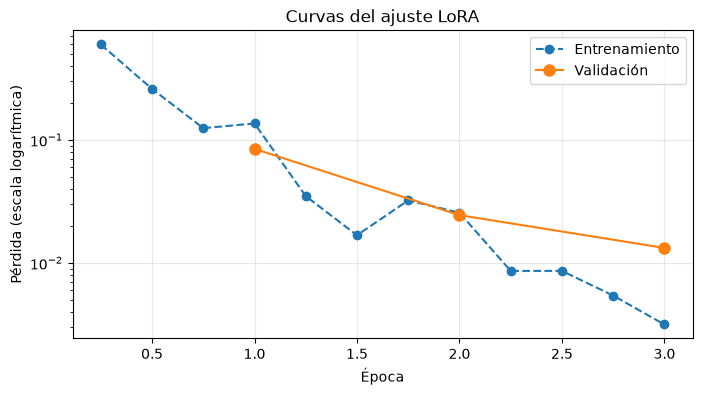

,Valor
Modelo base,Qwen/Qwen2.5-0.5B-Instruct
Precisión,float32
r,16
lora_alpha,32
Módulos,"q_proj, k_proj, v_proj, o_proj"
Épocas,3
Tasa de aprendizaje,0.0002
Lote,4
Pares de entrenamiento / validación,160 / 40
Parámetros entrenables,"2,162,688 de 496,195,456"


In [8]:
hist = pd.DataFrame(entrenador.state.log_history)
perdida_train = hist.dropna(subset=["loss"])[["epoch", "loss"]]
perdida_val = hist.dropna(subset=["eval_loss"])[["epoch", "eval_loss"]]
assert np.isfinite(perdida_train["loss"]).all() and np.isfinite(perdida_val["eval_loss"]).all(), "Hay NaN en las pérdidas"

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(perdida_train["epoch"], perdida_train["loss"], "o--", label="Entrenamiento")
ax.plot(perdida_val["epoch"], perdida_val["eval_loss"], "o-", ms=8, label="Validación")
ax.set_yscale("log")
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida (escala logarítmica)")
ax.set_title("Curvas del ajuste LoRA")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

display(pd.DataFrame({"Valor": {
    "Modelo base": NOMBRE_LLM, "Precisión": "float32", "r": HP_LORA["r"], "lora_alpha": HP_LORA["lora_alpha"],
    "Módulos": ", ".join(HP_LORA["target_modules"]), "Épocas": HP_TRAIN["num_train_epochs"], "Tasa de aprendizaje": HP_TRAIN["learning_rate"],
    "Lote": HP_TRAIN["per_device_train_batch_size"], "Pares de entrenamiento / validación": f"{len(PARES_TRAIN)} / {len(PARES_VAL)}",
    "Parámetros entrenables": f"{entrenables:,} de {totales:,}", "Pérdida de validación final": round(perdida_val["eval_loss"].iloc[-1], 4),
    "Tiempo (min)": round(segundos / 60, 1), "GPU": torch.cuda.get_device_name(0) if GPU else "CPU"}}))

## 4. Resultados
Las tres configuraciones reciben exactamente los mismos 30 mensajes de prueba, que el adaptador no vio.

In [9]:
modelo_lora.eval()
calif_lora = evaluar(M_LORA, modelo_lora, PROMPT_CORTO)

resultados = pd.DataFrame(filas).T
resultados.index.name = "Configuración"
resultados = resultados.rename(columns={c: f"Exactitud {c}" for c in CAMPOS})
resultados = resultados.astype(float).round(3)
resultados

,JSON válido,Exactitud nombre,Exactitud id_alumno,Exactitud area,Exactitud asunto,Exactitud urgente,Ticket exacto,s/mensaje
Configuración,,,,,,,,
Sin ajustar · prompt corto,0.0,0.867,0.933,0.000,0.033,0.433,0.000,0.426
Sin ajustar · prompt con reglas,1.0,0.967,0.933,0.400,0.267,0.900,0.067,0.336
"LoRA (r = 16, 3 épocas) · prompt corto",1.0,0.933,0.933,0.967,0.800,0.967,0.633,0.311


## 5. Conclusión
**Errores del modelo ajustado.** Cuántos errores tiene cada campo en cada configuración y cuáles son los casos de prueba en que falla el LoRA, con el campo equivocado.

In [10]:
errores_campo = pd.DataFrame({n: (1 - c[CAMPOS]).sum().astype(int) for n, c in [(M_CORTO, calif_corto), (M_REGLAS, calif_reglas), (M_LORA, calif_lora)]})
print("Errores por campo (de 30):")
display(errores_campo)

fallos = []
for i, (fila, salida) in enumerate(zip(calif_lora.to_dict("records"), salidas[M_LORA])):
    if not fila["Ticket exacto"]:
        d = leer_json(salida) or {}
        fallos.append({"#": i, "Mensaje": textos_prueba[i],
                       "Campos mal": ", ".join(f"{c}: {d.get(c)!r} (era {esperados[i][c]!r})" for c in CAMPOS if not fila[c])})
print(f"Casos de prueba en que falla el LoRA: {len(fallos)} de {len(PRUEBA)}")
display(pd.DataFrame(fallos).set_index("#"))

Errores por campo (de 30):


,Sin ajustar · prompt corto,Sin ajustar · prompt con reglas,"LoRA (r = 16, 3 épocas) · prompt corto"
nombre,4,1,2
id_alumno,2,2,2
area,30,18,1
asunto,29,22,6
urgente,17,3,1


Casos de prueba en que falla el LoRA: 11 de 30


,Mensaje,Campos mal
#,,
0,"ola buenas, soy karla mendez a2291 y no me deja inscrivir las materias de 5to semestre, ya intente 3 veces",nombre: 'Karlina Mendes' (era 'Karla Méndez')
3,"no puedo entrar a moodle me dice contraseña incorrecta y tengo examen en linea en una hora, urge. Diego Salas a1450","nombre: 'Diego Sáez' (era 'Diego Salas'), area: 'escolares' (era 'sistemas')"
7,"Profe, mi calificacion de estadistica salio 5 y yo saque 8 en el final, quien me ayuda? Rodrigo Nava A1733",id_alumno: 'A1NAV' (era 'A1733')
16,"hola, el sistema no me deja dar de alta Física II y tampoco me sale la constancia. Jimena Paredes A2902",asunto: 'inscripción de cursos' (era 'inscripción de materias')
17,"Mi matrícula es A1375. Ya pague y me sigue apareciendo adeudo, me van a bloquear la inscripción hoy si no se arregla, urgente",asunto: 'adeudo de matrícula' (era 'adeudo de colegiatura')
18,"se me olvido mi contraseña de moodle y no puedo reestablecerla, Ricardo Peña A2177",asunto: 'reestablecimiento de contraseña' (era 'acceso a Moodle')
19,"Buenas noches. Soy Daniela Ortiz (a2533). Saqué 9 en el examen de contabilidad pero en el sistema tengo 6, pido revisión",asunto: 'revisión de nota' (era 'revisión de calificación')
22,"pague dos veces la reinscripcion por error, como pido que me regresen uno? Óscar Ibarra A2365",asunto: 'reinscripción de estudios' (era 'cobro duplicado')
25,kiero cambiarme de grupo de ingles xq el profe no se presenta. Samuel Torres a1066,id_alumno: 1066 (era 'A1066')


**¿Qué olvidó el modelo?** Peticiones que **no son su tarea**, como conversación normal (sin *prompt* de sistema), con y sin el adaptador. `disable_adapter()` apaga el adaptador sin recargar el modelo, así que la única diferencia entre las dos columnas son las matrices de LoRA.

In [11]:
OTRAS = ["¿Cuál es la capital de Francia?", "Escribe un haiku sobre el otoño.", "Traduce al inglés: «La biblioteca abre a las ocho».",
         "¿Cuánto es 15 por 4?", "Dame tres consejos para estudiar para un examen."]


def charlar(modelo, peticiones, max_nuevos=80):
    prompts = [tok.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True) for p in peticiones]
    ent = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(modelo.device)
    with torch.no_grad():
        sal = modelo.generate(**ent, max_new_tokens=max_nuevos, do_sample=False, temperature=None, top_p=None, top_k=None, pad_token_id=tok.pad_token_id)
    return [t.strip() for t in tok.batch_decode(sal[:, ent["input_ids"].shape[1] :], skip_special_tokens=True)]


con_adaptador = charlar(modelo_lora, OTRAS)
with modelo_lora.disable_adapter():
    sin_adaptador = charlar(modelo_lora, OTRAS)

olvido = pd.DataFrame({"Petición": OTRAS, "Sin adaptador": sin_adaptador, "Con adaptador": con_adaptador})
olvido["¿Responde con un ticket JSON?"] = olvido["Con adaptador"].map(lambda s: leer_json(s) is not None)
display(olvido)

# Y la misma tarea fuera de su formato: una petición de la mesa de ayuda que no es un problema
pregunta = "¿A qué hora cierra la biblioteca los sábados?"
print(f"\nMensaje fuera del catálogo, con el prompt corto: {pregunta}")
print("  con adaptador:", generar_respuestas(modelo_lora, [pregunta], PROMPT_CORTO)[0])
with modelo_lora.disable_adapter():
    print("  sin adaptador:", generar_respuestas(modelo_lora, [pregunta], PROMPT_CORTO)[0][:300])

,Petición,Sin adaptador,Con adaptador,¿Responde con un ticket JSON?
0,¿Cuál es la capital de Francia?,"La capital de Francia es París.\n\nParís es el centro político, cultural y económico de Francia. Es conocida por su arquitectura históri...",La capital de Francia es París.,False
1,Escribe un haiku sobre el otoño.,"Levanta las hojas,\nOtoño se abraza con su luz,\nCielo pálido y verde.","albares son silenciosos,\nnubes cobran color de rosa,\notoño es un nuevo día.",False
2,Traduce al inglés: «La biblioteca abre a las ocho».,The library opens at eight o'clock.,"""the library opens at eight.""",False
3,¿Cuánto es 15 por 4?,15 por 4 es igual a 3.75.,15 por 4 es igual a 3.75.,False
4,Dame tres consejos para estudiar para un examen.,"Claro, aquí tienes tres consejos generales para mejorar tu rendimiento en el estudio:\n\n1. Planificación: Una de las mejores formas de ...","Claro, aquí te presento tres consejos fundamentales para estudiar para un examen:\n\n1. Planificación detallada: Es crucial tener una pl...",False



Mensaje fuera del catálogo, con el prompt corto: ¿A qué hora cierra la biblioteca los sábados?


  con adaptador: {"nombre": null, "id_alumno": null, "area": "escolares", "asunto": "fin de sesiones", "urgente": false, "fecha": null}


  sin adaptador: ```json
{
  "nombre": "Biblioteca",
  "id_alumno": "",
  "area": "Libros",
  "asunto": "Cierre de Biblioteca Sábado",
  "urgente": false
}
```


**Resumen.** Con los mismos 30 mensajes de prueba escritos aparte, el adaptador LoRA logra **63 % de tickets exactos** (19 de 30) y 100 % de JSON válido. El modelo sin ajustar logra 7 % con reglas y 0 % con el *prompt* corto. El ajuste entrenó 2.16 M de parámetros (0.44 % del modelo) en 1.3 minutos.

**La línea base.**
- **Con el *prompt* corto**, nunca da un JSON válido: lo envuelve en texto y en un bloque de código. Además inventa áreas («Matemáticas», «Cafe», «Examen en línea»), así que acierta el área en 0 de 30 mensajes.
- **Con reglas**, el formato se corrige (100 % de JSON válido) y la urgencia sube a 90 %, pero el modelo no respeta el catálogo: acierta el área en 40 % de los mensajes y el asunto en 27 %. Escribe asuntos como «inactividad en sistema» o «debe de pago de colegiatura», y áreas como «sistema» en lugar de «sistemas». Las reglas dicen qué hacer, pero un modelo de 0.5 B no las sigue con constancia.

**Errores del LoRA (11 de 30 mensajes, 12 campos).**
1. **Asunto parafraseado fuera del catálogo (6 errores, el principal).** Cuando el mensaje usa palabras distintas a las de las plantillas, el modelo escribe un asunto propio en lugar de elegir uno de la lista: «revisión de nota» por «revisión de calificación» (#19), «inscripción de cursos» (#16), «adeudo de matrícula» (#17). En dos casos copia la palabra del mensaje con todo y su error: «reestablecimiento de contraseña» (#18) y «error en el portal d alumnos» (#27). En #22, «pagué dos veces la reinscripción», se fijó en «reinscripción» y no en el cobro doble. El modelo nunca vio la lista cerrada de asuntos; la dedujo de 160 ejemplos, y esa restricción no quedó bien aprendida.
2. **Nombres y matrículas alterados (4 errores).** El modelo «corrige» nombres que no vio en el entrenamiento y los cambia: «karla mendez» → «Karlina Mendes» (#0) y «Diego Salas» → «Diego Sáez» (#3). En #7, la matrícula salió «A1NAV», una mezcla de la matrícula con el apellido Nava. En #25, «a1066» salió como el número 1066, sin la A: las plantillas siempre traían la A mayúscula pegada a los dígitos.
3. **Área equivocada (1 error).** En #3 (Moodle, «examen en línea») eligió escolares: la palabra «examen» pesó más que «moodle» escrito en minúsculas.
4. **Urgencia (1 error).** En #29 marcó como urgente un mensaje que no lo era («tengo un adeudo raro»).

Lo que sí aprendió bien: las cuatro áreas (97 %), la urgencia (97 %) y la regla de los dos temas, aunque ninguno de los mensajes de entrenamiento tenía dos temas. En los 6 mensajes de prueba con dos temas (#1, #5, #6, #16, #23, #29) eligió el tema correcto; en #16 lo nombró mal.

**¿Qué olvidó el modelo?**
- **En conversación normal**, sin *prompt* de sistema, **casi no olvidó nada**. Con el adaptador sigue respondiendo la capital de Francia, el haiku, la traducción y los consejos de estudio, y no contesta ninguna de las 5 peticiones con un ticket. Las respuestas sí cambian (el haiku y la traducción son distintos y más cortos): el adaptador mueve el comportamiento general, pero no lo destruye. El «15 por 4 es igual a 3.75» sale igual con y sin adaptador, así que es un error del modelo base, no del ajuste.
- **Lo que sí perdió es la capacidad de decir «esto no es un ticket».** Con el *prompt* de la tarea, una pregunta fuera del catálogo («¿A qué hora cierra la biblioteca los sábados?») se vuelve un ticket inventado: área escolares, asunto «fin de sesiones» y hasta un sexto campo, `"fecha"`, que nunca existió en el entrenamiento. Sin el adaptador tampoco responde bien (pone «Biblioteca» como nombre y «Libros» como área), pero el modelo ajustado se equivoca con más seguridad y con un formato que parece válido, y eso es más peligroso.

**Cómo lo mejoraría.** Agregaría al entrenamiento paráfrasis de cada asunto, matrículas en minúsculas, mensajes con dos temas y ejemplos fuera del catálogo con una salida propia. En producción, validaría cada ticket contra el catálogo: si el asunto o el área no están en la lista, el ticket pasa a revisión humana, como el validador del Avance 2.